# Tracking what a JEPA "knows": the residual stream + the Jacobian lens

This notebook opens up **Open-VLJEPA**, a community re-implementation of VL-JEPA (Meta's own weights are not public), and watches
how an image and a text query are processed *inside* the model, block by block.

## 1. What the model is

```
 image ──► V-JEPA 2 encoder (frozen) ──► 256 patch tokens (1024-d) ──► vis_proj ─┐
                                                                                 ├─► ONE sequence ─► 8 Llama blocks ─► final norm ─► mean-pool ─► out_proj ─► 1536-d prediction
 "Describe the image." ──► Llama tokenizer + Llama embedding table (2048-d) ─────┘     (bidirectional attention)
```

* The **predictor** is the *last 8 layers of Llama-3.2-1B* (hidden width 2048). Image patches and query-text tokens are concatenated
  into a single sequence, so every block lets image tokens attend to text tokens and vice versa.
* The model does **not generate words**. Its output is one 1536-d vector, which is trained to match the embedding of the *answer text*
  made by a separate text encoder (EmbeddingGemma, the "Y-encoder"). That target encoder is not used by this notebook's analysis.

## 2. The residual stream

Every token has a running vector `h` of 2048 numbers. Each Llama block *adds* to it (`h ← h + attention(h) + mlp(h)`), so `h` is
the model's working memory for that token. We record it **9 times**:

| state | meaning |
|---|---|
| 0 | the input: projected image patches + raw word embeddings (before any predictor block) |
| 1 … 8 | the stream right after predictor block 1 … 8 |

State 8 is what the output head reads. Watching states 0 → 8 shows an answer being built up.

## 3. The lens: reading the stream at any depth

A *lens* applies the model's **own readout** to an intermediate state, as if the model had to answer right now. We use two readouts:

* **Llama-vocabulary words (2048-d).** The predictor shares Llama's token-embedding table, which Llama ties to its output head. So any
  state (after the final norm) can be compared with all ~128k word embeddings, and the best-matching **actual words** are shown.
  This is the dictionary-free way to see what a token's state "is about".
* **Output space (1536-d).** `out_proj(norm(h))` applied per token. Because the head is linear after the norm, the *mean* of these
  per-token vectors equals the model's final prediction exactly. So each token's readout is its **direct contribution to the answer**.
  Projecting it on the final prediction direction gives the *lens heatmap* (red = pushes toward the answer, blue = pushes away).

## 4. The Jacobian lens: what the answer is *sensitive* to

The plain lens only shows what a state would contribute if read out *now*. It ignores what later blocks do with it. The **Jacobian lens**
asks a different question: *if this token's state at depth k were nudged, how much would the final answer move?*

* We take the model's own prediction, `pred`, and its unit direction `t = pred / |pred|`.
* We back-propagate the scalar `s = pred · t` (with `t` held fixed) through all later blocks, and read the gradient `∂s/∂h` at every
  token and every depth. (A cosine to `pred` itself would give an all-zero gradient, since it is already at its maximum, so a dot product
  is used. At this point `∂s/∂h` equals `∂|pred|/∂h`.)
* **Importance = Σ over channels of |gradient × activation|.** Bright = this token's state at this depth strongly shapes the output.

| | Lens (heatmap, words) | Jacobian lens |
|---|---|---|
| Question | what does this state say / contribute **if read out now**? | how much does the output **depend on** this state? |
| Counts later blocks? | no | yes (through the gradient) |
| Sign | yes (toward / away) | no (importance only) |
| A token bright in Jacobian but neutral in lens | acts **indirectly**, for example by being attended to by other tokens | |

## 5. What gets drawn

1. **Overview**: the input image, and mean residual norm of image vs text tokens through depth.
2. **5 × 9 grid** (one column per state): (1) PCA of the image-token stream as RGB, (2) residual norm per patch, (3) lens heatmap,
   (4) Jacobian lens heatmap, (5) top Llama-vocabulary words for the whole stream.
3. **Text-token matrices**: Jacobian importance and lens push of each query token (including the start token) per depth.
4. **Printed traces** of the whole-stream words through depth.
5. **V-JEPA 2 encoder PCA**: the image representation *before* the predictor.
6. **Cell 4 extras**: per-state word tables, a colour-coded word map with a ranked word-count table under it, and a tracker showing where a chosen word lights up.

## 6. Read the results with care

* Early states (0 to ~3) are noisy: the image patches only enter Llama's space through a learned projection, and the vocabulary head was
  not trained to read them.
* Everything is **self-referential**: the target is the model's own output, so you see what drives *its* prediction, not whether it is right.
* Image tokens are in vocabulary space only approximately. Treat words as hints about the direction of a state, not as captions.
* The first (start-of-sequence) text token often has a huge norm and attracts attention; it may dominate the text-token plots.

**Required:** EmbeddingGemma is gated on Hugging Face. Accept the licence at https://huggingface.co/google/embeddinggemma-300m and add a
Kaggle secret called `HF_TOKEN` (Add-ons → Secrets) with a read token.

## Cell 1: Setup

Installs libraries, holds **all user settings in one place**, logs in to Hugging Face, builds the Open-VLJEPA model from its GitHub code +
checkpoint, and defines the geometry constants (image size, patch grid, normalisation) used everywhere else.

In [1]:
# =====================================================================
# CELL 1: SETUP -- load Open-VLJEPA (V-JEPA 2 encoder + Llama predictor + Gemma text encoder)
# =====================================================================
# STEP 1  Install and import libraries.
# STEP 2  USER SETTINGS (everything you may want to change lives in this one block).
# STEP 3  Log in to Hugging Face (needed for the gated EmbeddingGemma download).
# STEP 4  Clone the Open-VLJEPA code, download its checkpoint, build the model, load the weights, freeze it.
# STEP 5  Define constants: image size, 16x16 patch grid, normalisation, number of residual-stream states.
!pip install -q -U transformers huggingface_hub pyyaml scikit-image

import os, sys, math, warnings, subprocess
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps
import transformers
warnings.filterwarnings("ignore")
print("transformers", transformers.__version__)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# ------------------------- USER SETTINGS -------------------------
IMAGE_PATH = "/kaggle/input/datasets/michel64leblond/autolumetrainingimages/training_dataset1/training_dataset1/training_dataset_256x256/image_00006.png"
                       # path to your image; set None to use the skimage astronaut photo
QUERY      = "Describe the image."   # text that enters the residual stream next to the image. It is tokenised, embedded
                                     # with Llama's embedding table, and appended after the image tokens, so it steers
                                     # how the image tokens are processed (every block attends across image + text)
NUM_FRAMES = 2                       # a still image is repeated to this many frames. 2 = exactly one V-JEPA 2 tubelet
                                     # (256 image tokens). More frames just duplicates the image and slows everything down

# --- word readout (Cell 2 / Cell 3 / Cell 4) ---
LENS_MODE  = "logit"                 # "logit"  = norm(h) @ E^T, what Llama's tied LM head would compute
                                     # "cosine" = nearest word embedding by angle (try if "logit" shows odd rare tokens)
WORDS_ONLY = True                    # keep only English-looking word pieces of 3+ letters (drops punctuation, code,
                                     # other scripts and special tokens). False = every token in the vocabulary
TOPK       = 6                       # how many words to list per readout

# --- Cell 4 extras ---
SHOW_STATES     = None               # None = print all 9 states, or a list such as [0, 4, 8]
WORD_MAP_STATES = [4, 6, 8]          # states for which the word map + ranked word-count table is drawn
TABLE_ROWS      = 10                 # how many of the most common top-1 words get a table row and an image colour
SHOW_PATCH_LABELS = False            # True = also write the word on every coloured patch (cluttered; the table is easier to read)
WATCH_WORDS     = ["rock", "sculpture", "rock stack"]   # words whose location in the image is tracked block by block
# -----------------------------------------------------------------

# --- STEP 3: Hugging Face login ---
HF_TOKEN = os.environ.get("HF_TOKEN")
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")     # reads the Kaggle secret
except Exception:
    pass
from huggingface_hub import login, hf_hub_download
if HF_TOKEN:
    login(HF_TOKEN)
else:
    print("WARNING: no HF_TOKEN found; gated model download will fail.")

# --- STEP 4: get the Open-VLJEPA code and build the model ---
REPO = "/kaggle/working/open-vljepa" if os.path.isdir("/kaggle/working") else "/content/open-vljepa"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "-q", "https://github.com/dion-jy/open-vljepa", REPO], check=True)
sys.path.insert(0, REPO)
from openvljepa.models.vljepa import OpenVLJEPA
from transformers import AutoTokenizer

ckpt_path = hf_hub_download("cun-bjy/open-vljepa", "best.pt")           # trained weights (~2 GB)
ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
cfg = ckpt["config"]                                                    # architecture settings stored with the checkpoint
# Same Llama-3.2-1B weights from an ungated community mirror, so you do not have to wait for Meta's approval.
# (Set to "meta-llama/Llama-3.2-1B" to use the official gated repo instead.)
LLAMA_REPO = "unsloth/Llama-3.2-1B"
cfg["predictor"]["llama_name"] = LLAMA_REPO

try:
    model = OpenVLJEPA(cfg["encoder"], cfg["y_encoder"], cfg["predictor"], torch_dtype=torch.float32)
except Exception as e:
    raise RuntimeError(
        "Could not build the model. Most likely the EmbeddingGemma licence has not "
        "been accepted for the account behind HF_TOKEN (see the top of the notebook). Original error: " + repr(e))
missing, unexpected = model.load_state_dict(ckpt["model_state_dict"], strict=False)
bad = [k for k in missing if not k.startswith("x_encoder.model.")]      # the V-JEPA 2 encoder is loaded from its own repo, so those keys may be "missing"
print(f"checkpoint loaded (epoch {ckpt.get('epoch', '?')}); non-frozen keys missing: {len(bad)}, unexpected: {len(unexpected)}")
model = model.float().to(device).eval()                                 # inference mode, fp32 (needed for clean gradients later)
for p in model.parameters():
    p.requires_grad_(False)                                             # we only differentiate w.r.t. activations, never weights

# Tokenizer for the QUERY text. Llama has no pad token, so reuse end-of-sequence.
tok_query = AutoTokenizer.from_pretrained(cfg["predictor"]["llama_name"])
if tok_query.pad_token is None:
    tok_query.pad_token = tok_query.eos_token

# --- STEP 5: geometry and normalisation constants ---
IMG   = cfg["data"]["image_size"]            # 256 pixels per side
MAXQ  = cfg["data"].get("max_query_len", 64) # queries are padded to this many tokens (padding is masked out everywhere)
GRID  = IMG // 16                            # 16 x 16 patches (each patch is 16x16 pixels)
MEAN  = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)   # ImageNet normalisation used by V-JEPA 2
STD   = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
pred_mod = model.predictor                   # the Llama-based predictor: this is where the residual stream lives
n_states = len(pred_mod.layers) + 1          # input embeddings + one state per predictor block = 9
print(f"joint residual stream: {n_states} states (input + {len(pred_mod.layers)} Llama blocks), width {pred_mod.hidden_size}")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
transformers 5.22.2
device: cuda


best.pt: reconstructing file:   0%|          |  0.00B / 2.13GB            

best.pt: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/785 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.30GB            

model.safetensors: downloading bytes:           |  0.00B            

... (13 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/459 [00:00<?, ?B/s]

joint residual stream: 9 states (input + 8 Llama blocks), width 2048


## Cell 2: Tools

Everything the analysis needs, defined once:

* **Vocabulary readout**: the Llama word-embedding table, a filter that keeps real-looking words, and `_top()` which returns the
  best-matching words for any set of stream vectors.
* **Input prep**: turn an image into frames the encoder accepts, and a query into token ids.
* **`StreamTap`**: forward hooks that record the residual stream at all 9 states.
* **`run_stream`** (plain forward pass) and **`run_stream_dot`** (forward + backward for the Jacobian lens).
* **`lens_tokens`** and **`grid_map`**: the per-token output-space readout and the token → 16×16 map reshaper.

In [2]:
# =====================================================================
# CELL 2: TOOLS -- vocabulary readout, input prep, residual-stream tap, lens, Jacobian
# =====================================================================
import re, collections

# ---------------------------------------------------------------------
# A. VOCABULARY READOUT: turn a 2048-d residual-stream vector into actual words
# ---------------------------------------------------------------------
# The predictor is the last 8 layers of Llama-3.2-1B and reuses Llama's token-embedding table. Llama ties that table to
# its output head, so the same matrix E (vocab x 2048) both embeds words going in and reads words coming out. That makes
# every residual-stream state directly comparable to ~128k word pieces. No hand-written candidate list is used anywhere.
E  = pred_mod.embed_tokens.weight.detach().float().to(device)      # (V, 2048): one row per token piece
Vn = E.shape[0]
En = F.normalize(E, dim=-1)                                        # unit-length rows, used for cosine mode
_raw = tok_query.convert_ids_to_tokens(list(range(Vn)))            # id -> piece string, e.g. "Ġhelmet"
vocab_str = [(t or "").replace("\u0120", "").replace("\u2581", "") for t in _raw]   # strip the leading-space markers
# Mask of pieces allowed in the readout: letters only, 3+ chars. Excludes punctuation, numbers, code, other scripts, <|special|>.
keep = torch.tensor([bool(re.fullmatch(r"[A-Za-z]{3,}", s)) if WORDS_ONLY else bool(s) for s in vocab_str], device=device)
print(f"vocabulary: {Vn} tokens, {int(keep.sum())} usable for readout, mode={LENS_MODE}")

@torch.no_grad()
def _top(x, k):
    """x: (N, 2048) FINAL-NORMED stream vectors -> (ids, scores), each (N, k), the k best words per row.
    logit mode : score = x . E[word]; shown as a softmax probability over the usable vocabulary.
    cosine mode: score = cosine(x, E[word])."""
    s = (F.normalize(x, dim=-1) @ En.T) if LENS_MODE == "cosine" else (x @ E.T)
    s = s.masked_fill(~keep, float("-inf"))                         # disallowed pieces can never win
    v, i = s.topk(k, dim=-1)
    if LENS_MODE != "cosine":
        v = torch.exp(v - torch.logsumexp(s, dim=-1, keepdim=True)) # log-softmax -> probability
    return i.cpu(), v.cpu()

def _pairs(i, v):
    """ids + scores of ONE row -> list of (word, score)."""
    return [(vocab_str[a], b) for a, b in zip(i.tolist(), v.tolist())]

def _fmt(i, v, n=None):
    """Same as _pairs but as one printable string: 'word (0.31), word (0.12), ...'"""
    return ", ".join(f"{w} ({p:.2f})" for w, p in _pairs(i, v)[:n])

# ---------------------------------------------------------------------
# B. INPUT PREP
# ---------------------------------------------------------------------
def prep_image(img_pil):
    """PIL image -> (cropped 256x256 PIL image for display, normalised frames tensor (1, T, 3, H, W) for the encoder)."""
    img = ImageOps.fit(img_pil.convert("RGB"), (IMG, IMG))          # centre-crop + resize to 256x256
    t = (TF.to_tensor(img) - MEAN) / STD
    frames = t[None, None].expand(1, NUM_FRAMES, -1, -1, -1).contiguous().to(device)   # repeat the still across time
    return img, frames

def prep_query(text):
    """Text -> Llama token ids and attention mask, padded to MAXQ (padding is masked out of attention and pooling)."""
    q = tok_query(text, max_length=MAXQ, padding="max_length", truncation=True, return_tensors="pt")
    return q["input_ids"].to(device), q["attention_mask"].to(device)

# ---------------------------------------------------------------------
# C. RESIDUAL-STREAM TAP
# ---------------------------------------------------------------------
class StreamTap:
    """Records the joint residual stream with forward hooks (no change to the model's computation):
       * a pre-hook on block 0 grabs its INPUT                                  -> state 0
       * a post-hook on every block grabs its OUTPUT                            -> states 1..8
    When keep_grad is True each grabbed tensor also calls retain_grad(), so after .backward() every state has a .grad."""
    def __init__(self, predictor):
        self.states, self.keep_grad = [], False
        self.handles = [predictor.layers[0].register_forward_pre_hook(self._pre)]
        for layer in predictor.layers:
            self.handles.append(layer.register_forward_hook(self._post))
    def _grab(self, h):
        if self.keep_grad and h.requires_grad:
            h.retain_grad()
        self.states.append(h)
    def _pre(self, module, args):
        if not args:
            raise RuntimeError("predictor block received its hidden state as a keyword; adapt StreamTap._pre")
        self._grab(args[0])
    def _post(self, module, args, output):
        self._grab(output[0] if isinstance(output, tuple) else output)

tap = StreamTap(pred_mod)

def run_stream(vis, ids, mask):
    """Plain forward pass (no gradients). Returns the model's prediction (1, 1536) and the list of 9 states, each (1, L, 2048),
    where L = 256 image tokens + MAXQ query slots."""
    tap.states, tap.keep_grad = [], False
    with torch.no_grad():
        pred = pred_mod(vis, ids, mask)
    return pred, tap.states

def run_stream_dot(vis, ids, mask, t_hat):
    """Forward + backward for the JACOBIAN LENS.
    Scalar s = pred . t_hat, where t_hat = pred/|pred| is the model's own output direction (held fixed). Back-propagating s
    leaves a gradient ds/dh on every recorded state. (cos(pred, pred) would give a zero gradient because it is already at its
    maximum, so a dot product is used. At this point ds/dh equals d|pred|/dh.)"""
    tap.states, tap.keep_grad = [], True
    vis = vis.detach().clone().requires_grad_(True)                 # gives the graph something to differentiate through
    with torch.enable_grad():
        pred = pred_mod(vis, ids, mask)
        (pred * t_hat[None]).sum().backward()
    tap.keep_grad = False
    return pred.detach(), tap.states

# ---------------------------------------------------------------------
# D. LENS + LAYOUT HELPERS
# ---------------------------------------------------------------------
def lens_tokens(h):
    """OUTPUT-SPACE LENS: apply the model's own output head (final norm + out_proj) to any layer's tokens -> (1, L, 1536).
    The head is linear after the norm, so the masked MEAN of these per-token vectors equals the final prediction exactly.
    Each token's readout is therefore its direct contribution to the answer."""
    return pred_mod.out_proj(pred_mod.norm(h))

def grid_map(x):
    """(Nv,) per-image-token values -> (16, 16) map. If there are several tubelets in time, average over them."""
    return x.reshape(-1, GRID, GRID).mean(0)

vocabulary: 128256 tokens, 68150 usable for readout, mode=logit


## How to interpret the results: one image, or 256 patches?

**Both, in a specific way.** The model's *answer* treats the image as a single entity. Its *inside* works on 256 patches that constantly mix.

**Inside the model: a set of patches that all see each other**
* The V-JEPA 2 encoder is a transformer over the 256 patch tokens, so every patch already carries context from the whole image.
* In the predictor, attention runs in both directions across all 256 image tokens and the query tokens, in all 8 blocks. By state 8 a patch's
  vector blends "what is here" with "what the whole scene is about".

**At the output: one entity**
* There is no CLS or summary token. The prediction is the plain average of every real token's readout (image and query together), passed
  through `out_proj` into one 1536-d vector. Each token gets a vote of roughly 1/261.
* The model was trained only on that pooled vector. Nothing taught individual patches to be labels for their own region.

**What this means for each plot**

| view | reads the image as | how to interpret |
|---|---|---|
| whole-stream words (grid row 5, first line of the Cell 4 tables) | **one entity** | closest to the model's actual answer |
| PCA, residual norm, lens heatmap, Jacobian heatmap | **a set of patches** | shows how the single answer is *distributed* across patches |
| word map + count table, patch top-1 votes, word tracker | **a set of patches** | shows what each patch's state resembles as a word, not what is in that spot of the picture |

**Cautions**
* A patch's word can reflect global context rather than its own pixels. Some background patches act as storage for scene-level information,
  so a bright patch on empty sky does not mean the sky matters locally.
* In later blocks many patches drift toward the same words, because the output is an average and the stream is shaped to serve it. A word
  map filling with one word is partly this convergence.
* To see how much one region matters *locally*, use the **Jacobian lens** (sensitivity of the output to that patch's state), not the word map.

## Cell 3: Run the image + text through the stream and draw the results

* **`analyze()`** does all the computing: encode the image, run the stream once (lens and PCA readouts for each of the 9 states),
  then run it a second time with gradients (Jacobian lens).
* **`show()`** draws the overview, the 5 × 9 grid, the text-token matrices, the printed word traces, and the encoder PCA.

query: 'Describe the image.'  |  256 image tokens + 5 text tokens in one residual stream
sanity: lens(last block) vs model output cosine = 1.0000 (should be ~1)



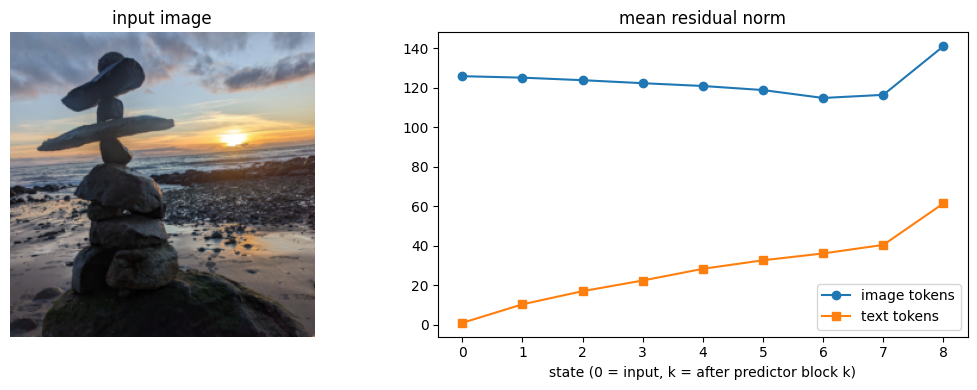

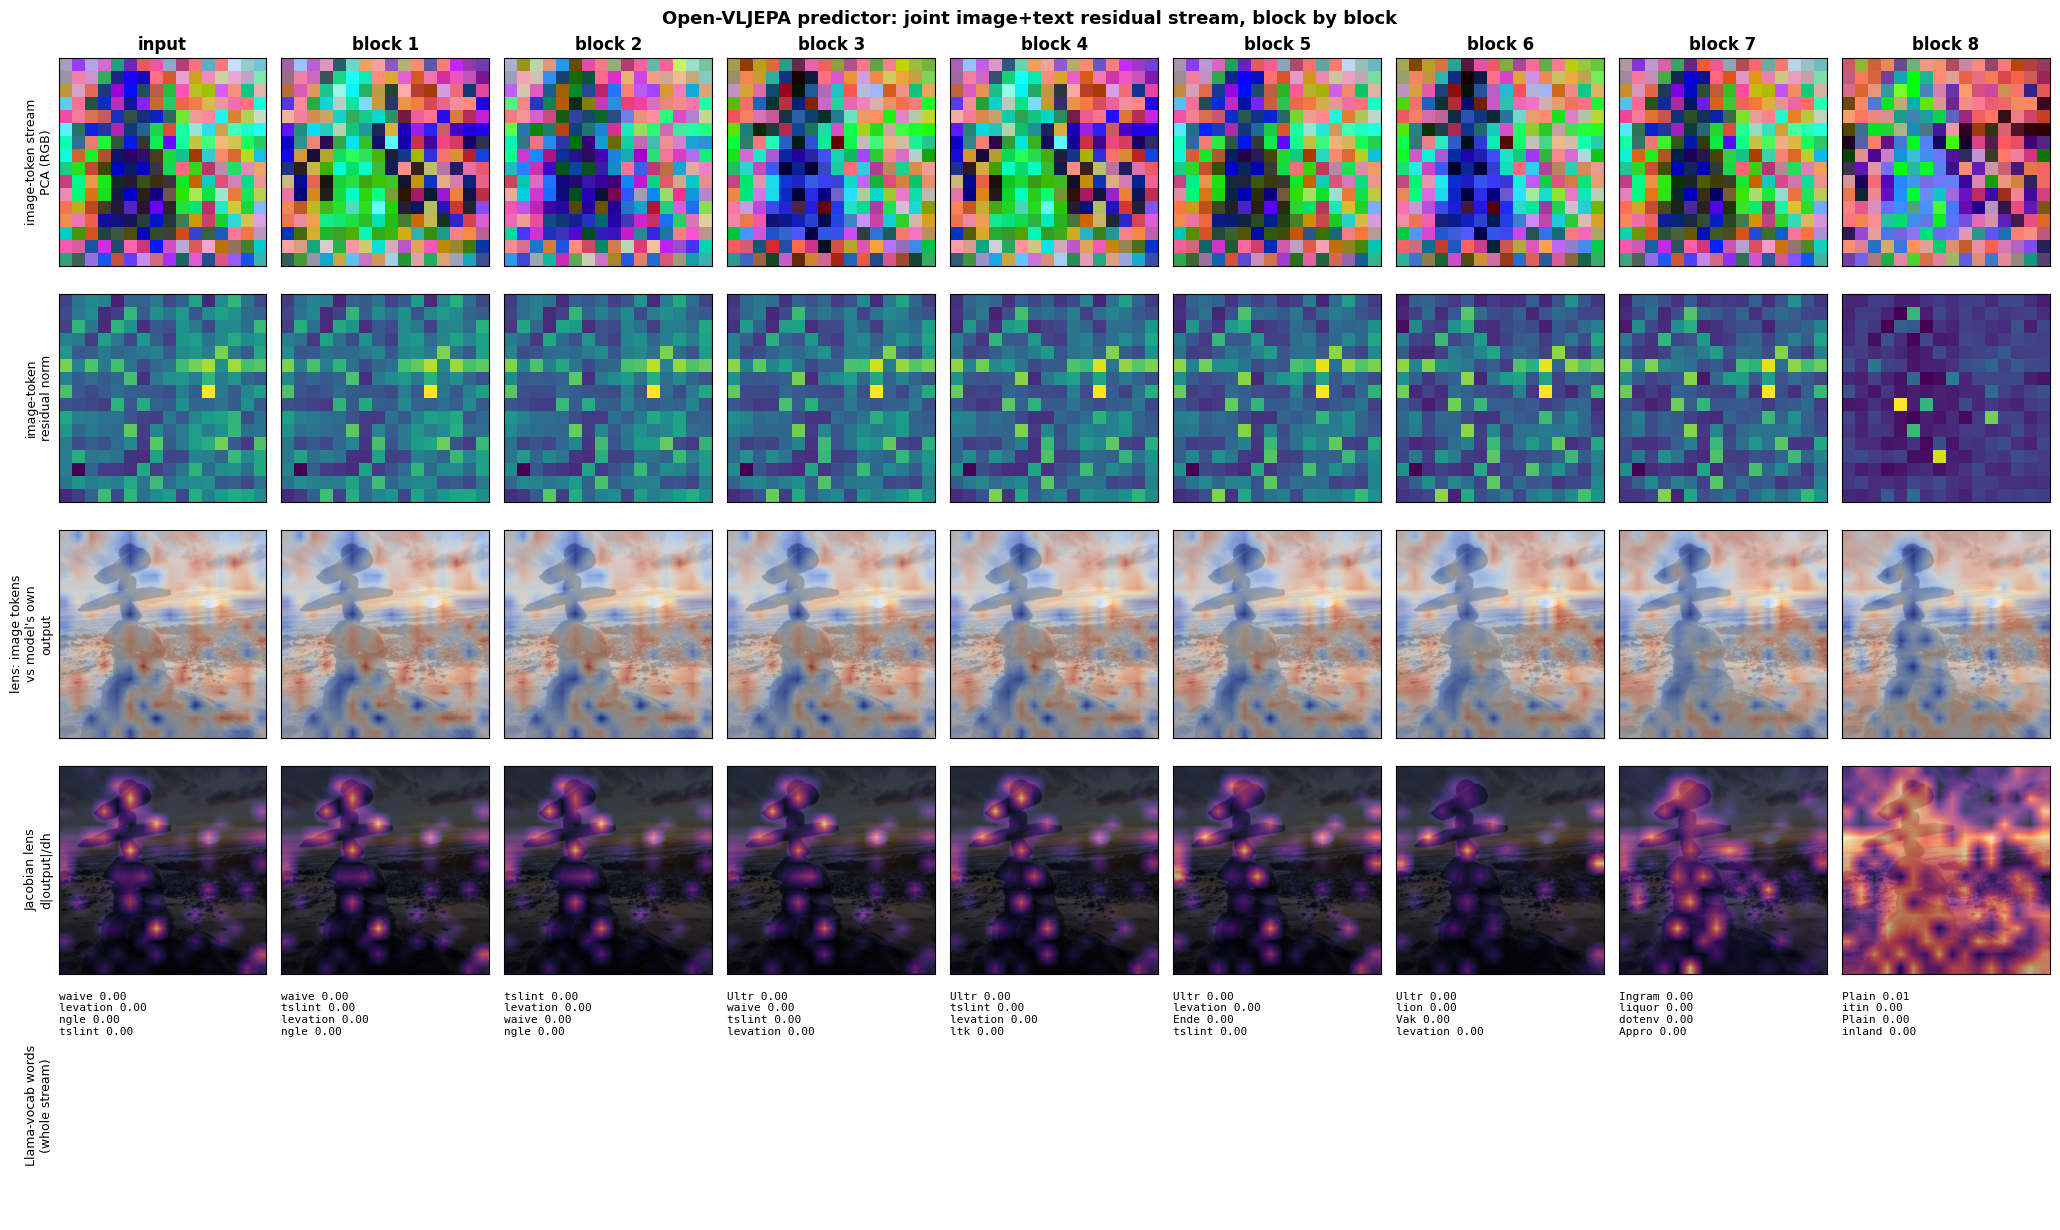

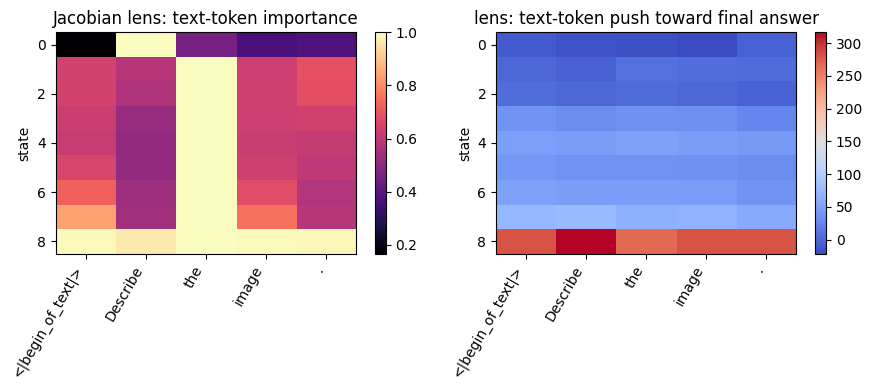

Whole-stream readout (Llama vocabulary) through depth:
  state 0: waive (0.00), levation (0.00), ngle (0.00)
  state 1: waive (0.00), tslint (0.00), levation (0.00)
  state 2: tslint (0.00), levation (0.00), waive (0.00)
  state 3: Ultr (0.00), waive (0.00), tslint (0.00)
  state 4: Ultr (0.00), tslint (0.00), levation (0.00)
  state 5: Ultr (0.00), levation (0.00), Ende (0.00)
  state 6: Ultr (0.00), lion (0.00), Vak (0.00)
  state 7: Ingram (0.00), liquor (0.00), dotenv (0.00)
  state 8: Plain (0.01), itin (0.00), Plain (0.00)


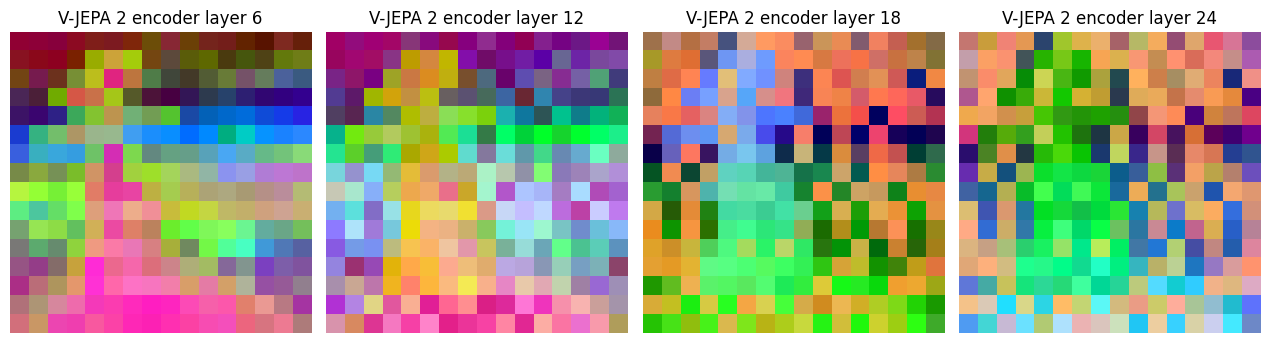

In [3]:
# =====================================================================
# CELL 3: RUN -- image + text through the joint residual stream
# =====================================================================
def analyze(img_pil, query):
    # ---- STEP 1: inputs ------------------------------------------------------------------------------
    img, frames = prep_image(img_pil)
    with torch.no_grad():
        vis = model.x_encoder(frames)                       # (1, Nv, 1024) V-JEPA 2 patch tokens; Nv = 256 for one tubelet
    ids, mask = prep_query(query)
    Nv, Lq = vis.shape[1], ids.shape[1]
    valid = mask[0].bool()                                  # which query slots hold real tokens (start token + words)
    fm = torch.cat([torch.ones(1, Nv, device=device), mask.float()], dim=1)   # (1, Nv+Lq): 1 for every real token
    denom = fm.sum()                                        # number of real tokens; the model mean-pools over these

    # ---- STEP 2: one forward pass, tapping all 9 residual-stream states -------------------------------
    pred, states = run_stream(vis, ids, mask)               # pred is the model's own 1536-d output

    # ---- STEP 3: read every state (the LENS and the PCA/norm views) ----------------------------------
    infos = []
    for k, h in enumerate(states):
        h = h.detach()
        z = lens_tokens(h)                                  # (1, L, 1536): per-token output-space readout
        pooled = (z * fm[..., None]).sum(1)[0] / denom      # masked mean over tokens = the model's output if it stopped here
        zv = z[0, :Nv]                                      # image-token part of the readout (used for the lens heatmap)
        hn = pred_mod.norm(h)[0]                            # (L, 2048) final-normed state = the space of Llama's embeddings
        hv = hn[:Nv]                                        # image tokens only
        pooled_h = (hn * fm[0][:, None]).sum(0) / denom     # the 2048-d vector that out_proj would receive
        wi, wv = _top(pooled_h[None], TOPK)                 # best Llama-vocabulary words for the whole stream

        # PCA of the image tokens -> 3 numbers per patch -> RGB. Patches with similar colours have similar states.
        Pc = hv - hv.mean(0)
        _, _, V = torch.pca_lowrank(Pc, q=6, center=False)
        rgb = (Pc @ V[:, :3]).cpu().numpy()
        lo, hi = np.percentile(rgb, 2, axis=0), np.percentile(rgb, 98, axis=0)   # robust 2-98% stretch per component
        rgb = np.clip((rgb - lo) / (hi - lo + 1e-8), 0, 1)
        rgb = rgb.reshape(-1, GRID, GRID, 3).mean(0)

        infos.append(dict(
            pooled=pooled, words=_pairs(wi[0], wv[0]), zv=zv, rgb=rgb,
            norm=grid_map(h[0, :Nv].norm(dim=-1)).cpu().numpy(),                         # raw residual norm per patch
            vis_norm=float(h[0, :Nv].norm(dim=-1).mean()),                               # mean norm, image tokens
            txt_norm=float(h[0, Nv:][valid].norm(dim=-1).mean()),                        # mean norm, text tokens
            ztxt=z[0, Nv:][valid]))                                                      # query-token readouts

    # Sanity check: the lens at the last block must reproduce the model's real output (cosine should be ~1).
    sanity = F.cosine_similarity(infos[-1]["pooled"][None], pred.float(), dim=-1).item()

    # ---- STEP 4: the target = the model's OWN output direction ---------------------------------------
    final_words = infos[-1]["words"]
    target_name = "model output"
    t_hat = F.normalize(pred[0].float(), dim=-1)            # unit vector along the model's prediction

    # ---- STEP 5: LENS heatmap: how much each image token pushes the output along t_hat ----------------
    for inf in infos:
        c = inf["zv"] @ t_hat                               # projection of each image token's readout on the answer direction
        c = grid_map(c).cpu().numpy()
        inf["heat"] = (c - c.mean()) / (c.std() + 1e-6)     # z-score per state so depths are comparable. red = toward, blue = away

    # ---- STEP 6: JACOBIAN LENS: second pass with gradients -------------------------------------------
    _, gstates = run_stream_dot(vis, ids, mask, t_hat)
    for k, inf in enumerate(infos):
        h, g = gstates[k].detach()[0], gstates[k].grad[0]   # state and d(output)/d(state), each (L, 2048)
        imp = (g * h).abs().sum(-1)                         # per-token importance = sum over channels |gradient x activation|
        jm = grid_map(imp[:Nv]).cpu().numpy()
        inf["jac"] = jm / (jm.max() + 1e-12)                # image tokens as a 16x16 map, scaled to 0..1
        ti = imp[Nv:][valid]
        inf["jac_txt"] = (ti / (ti.max() + 1e-12)).cpu().numpy()          # query tokens, scaled to 0..1
        inf["con_txt"] = (inf["ztxt"] @ t_hat).cpu().numpy()              # query tokens' direct (lens) push toward the output

    # readable names for the query tokens (start token + words)
    toks = [t.replace("\u0120", "").replace("\u2581", "") for t in tok_query.convert_ids_to_tokens(ids[0][valid].tolist())]
    return dict(img=img, infos=infos, toks=toks, target=target_name, final_words=final_words,
                sanity=sanity, Nv=Nv, query=query, frames=frames)


def show(res):
    img_np, infos = np.asarray(res["img"]), res["infos"]
    n = len(infos)
    print(f"query: '{res['query']}'  |  {res['Nv']} image tokens + {len(res['toks'])} text tokens in one residual stream")
    print(f"sanity: lens(last block) vs model output cosine = {res['sanity']:.4f} (should be ~1)\n")

    # --- FIGURE 1: overview ---
    # left: the image the model saw. right: how big the stream vectors are at each depth (image vs text tokens).
    # A text token with a huge norm is usually the start-of-sequence token acting as an attention sink.
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].imshow(img_np); ax[0].axis("off"); ax[0].set_title("input image")
    ax[1].plot(range(n), [i["vis_norm"] for i in infos], "o-", label="image tokens")
    ax[1].plot(range(n), [i["txt_norm"] for i in infos], "s-", label="text tokens")
    ax[1].set_xlabel("state (0 = input, k = after predictor block k)"); ax[1].set_title("mean residual norm"); ax[1].legend()
    plt.tight_layout(); plt.show()

    # --- FIGURE 2: the 5 x 9 grid (one column per state, left = input, right = after block 8) ---
    #  row 1  PCA colours of the image-token stream: similar colour = similar state; coherent regions = the stream has grouped them
    #  row 2  residual norm per patch: where the stream has accumulated the most
    #  row 3  LENS: red = this patch pushes the output toward the final answer, blue = pushes away
    #  row 4  JACOBIAN LENS: bright = the final output is very sensitive to this patch's state at this depth
    #  row 5  top Llama-vocabulary words of the whole stream (image + text) if the model were read out at this depth
    fig, axes = plt.subplots(5, n, figsize=(2.3 * n, 12.5))
    rows = ["image-token stream\nPCA (RGB)", "image-token\nresidual norm",
            "lens: image tokens\nvs model's own\noutput", "Jacobian lens\nd|output|/dh", "Llama-vocab words\n(whole stream)"]
    for c, inf in enumerate(infos):
        axes[0, c].imshow(inf["rgb"], interpolation="nearest"); axes[0, c].set_title("input" if c == 0 else f"block {c}", fontweight="bold")
        axes[1, c].imshow(inf["norm"], cmap="viridis", interpolation="nearest")
        axes[2, c].imshow(img_np, extent=(-0.5, GRID - 0.5, GRID - 0.5, -0.5))
        axes[2, c].imshow(inf["heat"], cmap="coolwarm", vmin=-2.5, vmax=2.5, alpha=0.6, interpolation="bilinear")
        axes[3, c].imshow(img_np, extent=(-0.5, GRID - 0.5, GRID - 0.5, -0.5))
        axes[3, c].imshow(inf["jac"], cmap="magma", alpha=0.7, interpolation="bilinear")
        for r in range(5):
            axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        for s in axes[4, c].spines.values():
            s.set_visible(False)
        axes[4, c].text(0, 1, "\n".join(f"{w[:14]} {p:.2f}" for w, p in inf["words"][:4]), va="top", fontsize=8, family="monospace")
    for r, name in enumerate(rows):
        axes[r, 0].set_ylabel(name, fontsize=9)
    fig.suptitle("Open-VLJEPA predictor: joint image+text residual stream, block by block", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

    # --- FIGURE 3: what the QUERY tokens do (rows = depth, columns = tokens) ---
    # left : Jacobian importance of each text token (does the output depend on it?)
    # right: lens push of each text token toward the final output (red = toward, blue = away)
    toks = res["toks"]
    fig, ax = plt.subplots(1, 2, figsize=(max(9, 0.9 * len(toks) * 2), 4))
    jac = np.stack([i["jac_txt"] for i in infos]); con = np.stack([i["con_txt"] for i in infos])
    for a, M, title, cm in ((ax[0], jac, "Jacobian lens: text-token importance", "magma"), (ax[1], con, "lens: text-token push toward final answer", "coolwarm")):
        im = a.imshow(M, aspect="auto", cmap=cm); a.set_title(title)
        a.set_xticks(range(len(toks))); a.set_xticklabels(toks, rotation=60, ha="right"); a.set_ylabel("state"); plt.colorbar(im, ax=a)
    plt.tight_layout(); plt.show()

    # --- TEXT TRACE: the whole-stream words at every depth ---
    print("Whole-stream readout (Llama vocabulary) through depth:")
    for k, inf in enumerate(infos):
        print(f"  state {k}: " + ", ".join(f"{w} ({p:.2f})" for w, p in inf["words"][:3]))

    # --- FIGURE 4: V-JEPA 2 encoder PCA (the image data BEFORE it reaches the predictor) ---
    # Same PCA-to-RGB idea, applied to four layers inside the frozen vision encoder. Shows what structure the encoder already found.
    try:
        with torch.no_grad():
            hs = model.x_encoder.model(res["frames"], skip_predictor=True, output_hidden_states=True).hidden_states
        picks = sorted(set(int(round(v)) for v in np.linspace(len(hs) / 4, len(hs) - 1, 4)))
        fig, ax = plt.subplots(1, len(picks), figsize=(3.2 * len(picks), 3.4))
        for a, l in zip(np.atleast_1d(ax), picks):
            x = hs[l][0].float(); x = x - x.mean(0)
            _, _, V = torch.pca_lowrank(x, q=6, center=False)
            rgb = (x @ V[:, :3]).cpu().numpy(); lo, hi = np.percentile(rgb, 2, 0), np.percentile(rgb, 98, 0)
            rgb = np.clip((rgb - lo) / (hi - lo + 1e-8), 0, 1).reshape(-1, GRID, GRID, 3).mean(0)
            a.imshow(rgb, interpolation="nearest"); a.set_title(f"V-JEPA 2 encoder layer {l}"); a.axis("off")
        plt.tight_layout(); plt.show()
    except Exception as e:
        print("(encoder PCA skipped:", type(e).__name__, str(e)[:120], ")")


# ---- run it ----
if IMAGE_PATH:
    src = Image.open(IMAGE_PATH)
else:
    from skimage import data
    src = Image.fromarray(data.astronaut())
res = analyze(src, QUERY)
show(res)

## Cell 4: Word-level views of the stream (optional extras)

Needs Cell 3 to have run (it reuses `res`). Three views, all read through Llama's vocabulary:

1. **Per-state tables**: for every depth, the top words of the whole stream, of the mean image token, the most common top-1 word across
   the 256 patches, and what each query token turns into.
2. **Word map + table**: every patch gets its top-1 word; the most common words are counted, ranked and colour-coded. Under each image is a table
   (word, patch count, share, mean score) whose colours match the tint on the image. Controlled by `WORD_MAP_STATES` and `TABLE_ROWS`.
3. **Word tracker**: for each word in `WATCH_WORDS`, a heatmap of how strongly each patch matches that word, at every depth.

query: 'Describe the image.'   scores = prob

--- state 0 (input) ---
  whole stream (pooled) : waive (0.00), levation (0.00), ngle (0.00), tslint (0.00), eselect (0.00), GENCY (0.00)
  mean of image tokens  : waive (0.00), levation (0.00), ngle (0.00), tslint (0.00), eselect (0.00), GENCY (0.00)
  patch top-1 votes     : mamma x7, ltk x6, structuring x6, prit x5, reckon x4, ASTER x4
  text tokens           : <|begin_of_text|> -> vrou (0.01), Animalia (0.01) | Describe -> Describe (1.00), Describe (0.00) | the -> the (1.00), and (0.00) | image -> image (1.00), image (0.00) | . -> and (1.00), for (0.00)

--- state 1 (after block 1) ---
  whole stream (pooled) : waive (0.00), tslint (0.00), levation (0.00), ngle (0.00), eselect (0.00), structuring (0.00)
  mean of image tokens  : waive (0.00), tslint (0.00), levation (0.00), ngle (0.00), eselect (0.00), structuring (0.00)
  patch top-1 votes     : ltk x9, structuring x7, essenger x5, mamma x5, prit x5, devil x4
  text tokens           : 

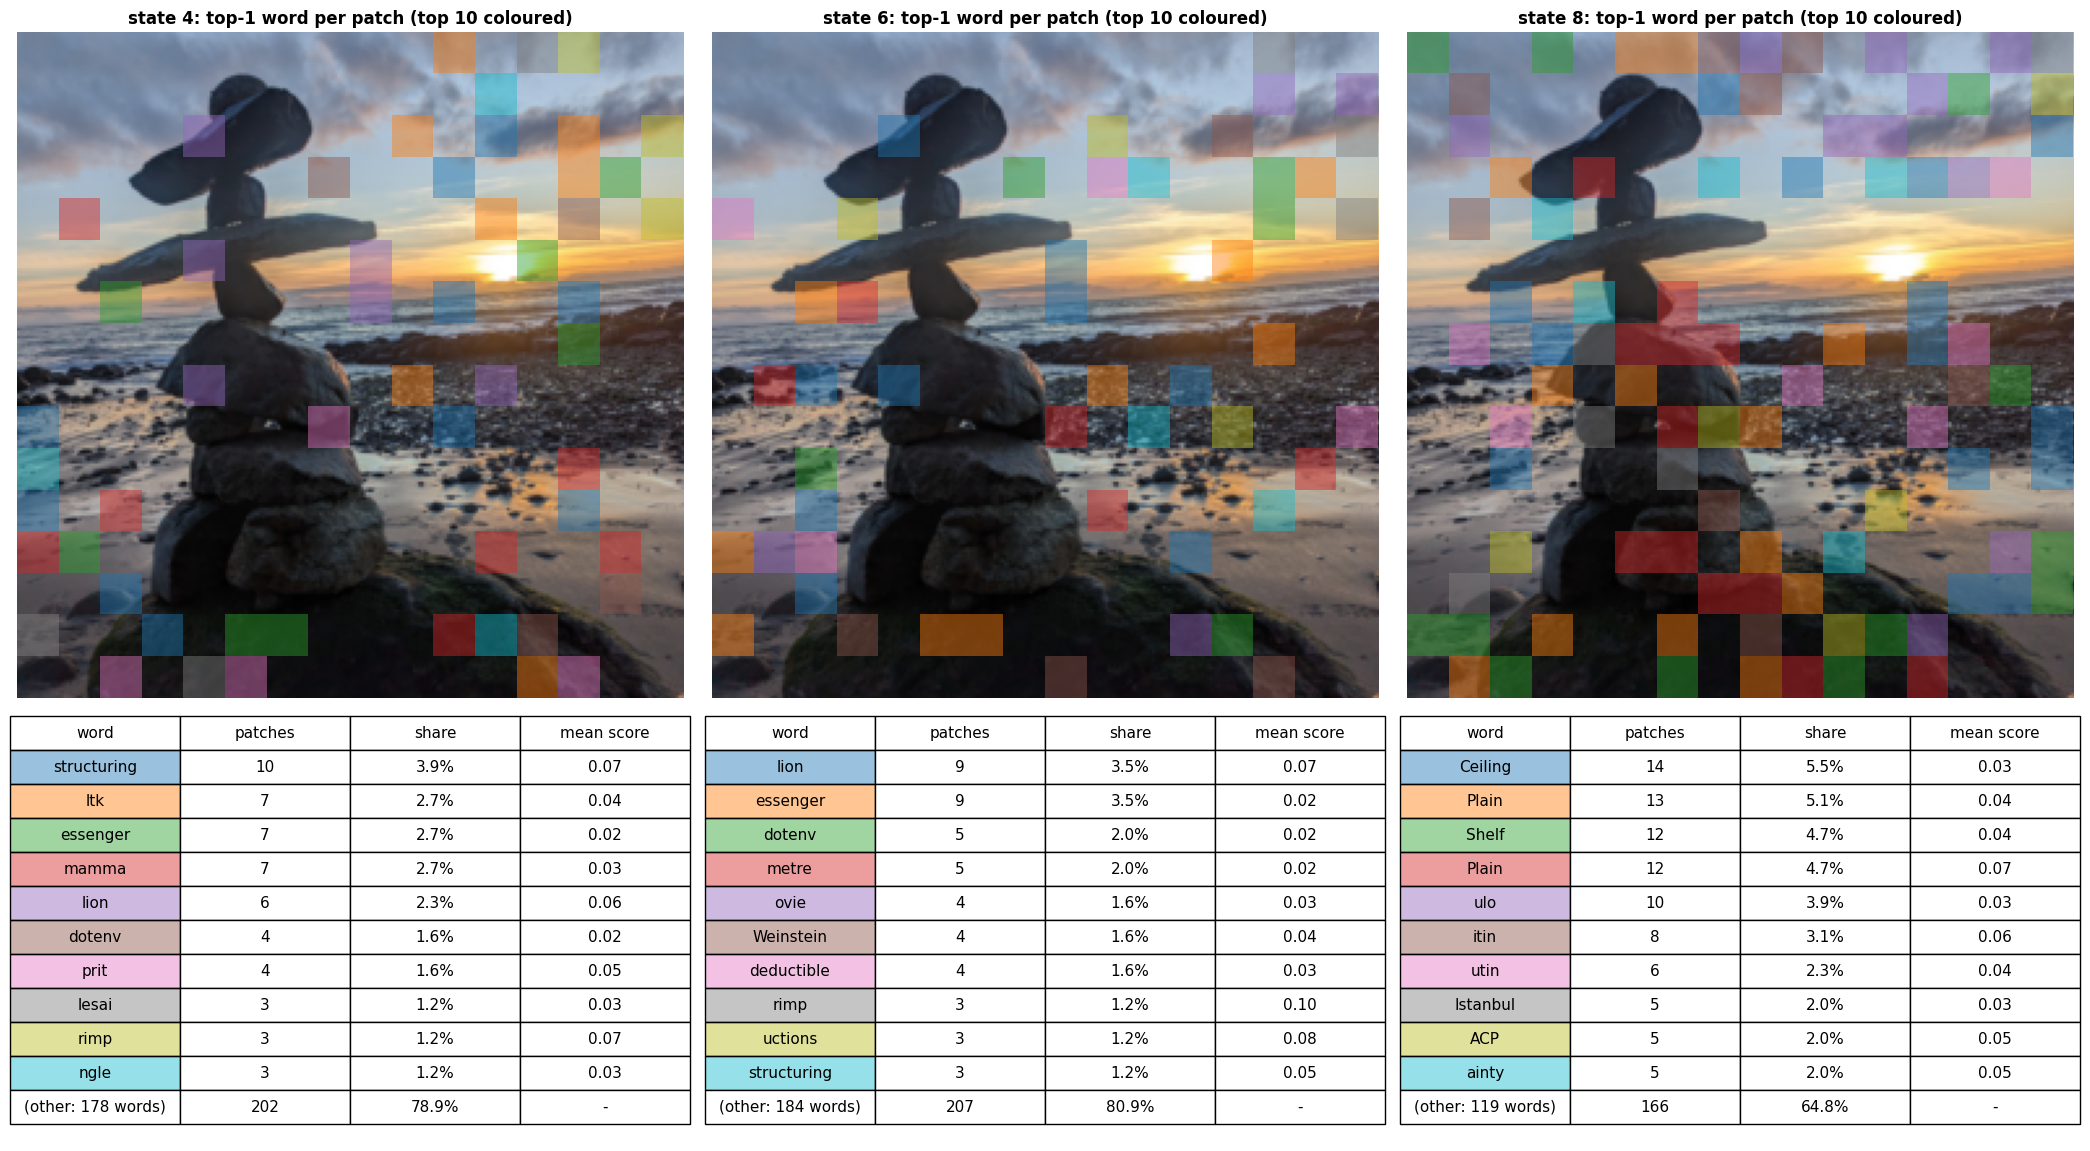

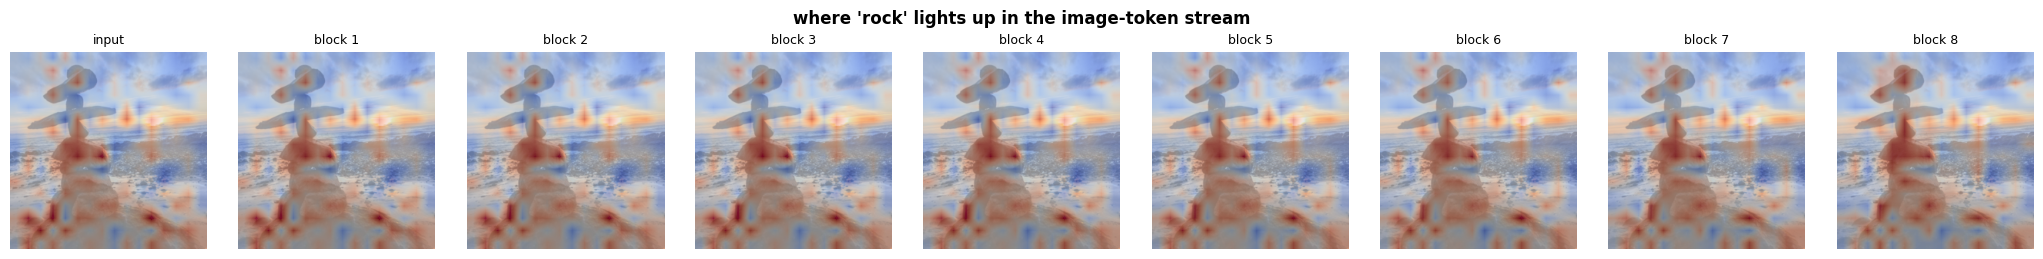

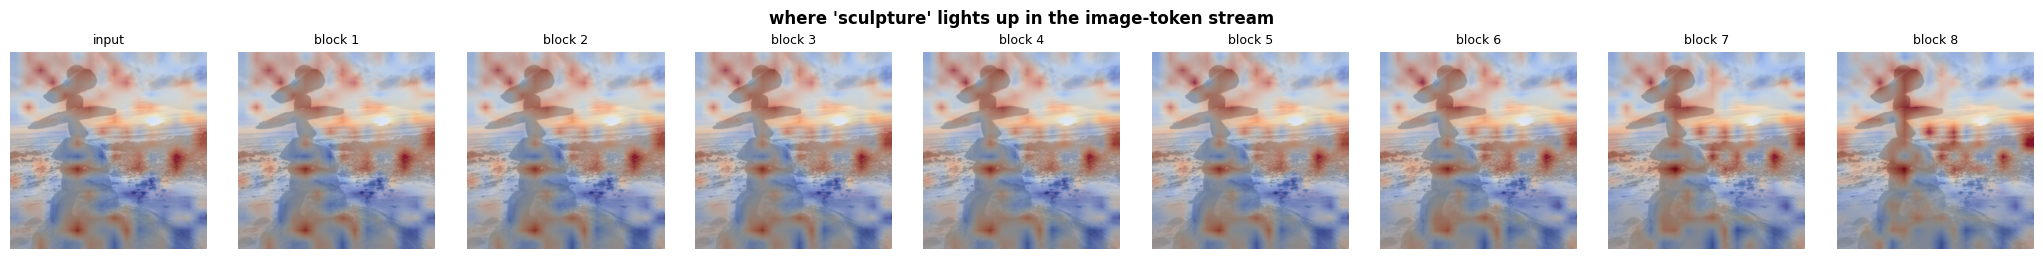

'rock stack' is 2 tokens ['Ġrock', 'Ġstack']; using the first piece


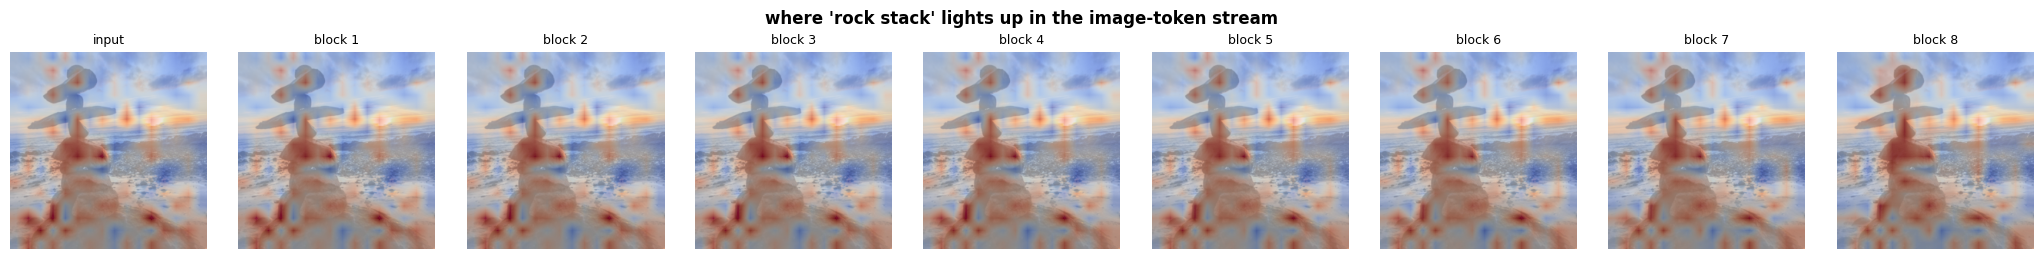

In [4]:
# =====================================================================
# CELL 4: WORD LENS -- read image + text tokens as actual Llama vocabulary words
# =====================================================================
# Uses the settings SHOW_STATES, WORD_MAP_STATES, TABLE_ROWS, WATCH_WORDS (Cell 1) and the vocabulary tools (Cell 2).
#
# WHOLE IMAGE OR 256 PATCHES?  (see the interpretation note above Cell 3)
#   * The model's ANSWER is one entity: the mean of all token readouts, with no summary token. So the "whole stream (pooled)" line
#     below is the view closest to what the model actually says about the image.
#   * Everything else here is PER PATCH: each of the 256 patch states is read out as a word on its own. Patches attend to each other in
#     every block, so a patch's word can reflect scene-level context and not only its own pixels, and in later blocks many patches
#     converge on the same words because the output is an average. Read the word map and table as a pattern, not as 256 captions.
#   * To ask how much a specific REGION matters, use the Jacobian lens from Cell 3 instead.
import matplotlib.patheffects as pe

@torch.no_grad()
def _stream(res):
    """Re-run the stream once and return: final-normed states (list of 9 tensors (L, 2048)), Nv, valid-token mask, token weights."""
    vis = model.x_encoder(res["frames"])
    ids, mask = prep_query(res["query"])
    Nv = vis.shape[1]
    _, states = run_stream(vis, ids, mask)
    hn = [pred_mod.norm(h.detach())[0] for h in states]      # the final norm puts states in the space Llama's embeddings live in
    fm = torch.cat([torch.ones(Nv, device=device), mask[0].float()])
    return hn, Nv, mask[0].bool(), fm


@torch.no_grad()
def word_lens(res, states_to_show=SHOW_STATES):
    hn_all, Nv, valid, fm = _stream(res)
    toks = res["toks"]
    score_name = "cosine" if LENS_MODE == "cosine" else "prob"
    print(f"query: '{res['query']}'   scores = {score_name}\n")

    for k in (range(len(hn_all)) if states_to_show is None else states_to_show):
        hn = hn_all[k]
        pooled = (hn * fm[:, None]).sum(0) / fm.sum()                 # whole stream (image + text), what out_proj receives
        i, v = _top(torch.stack([pooled, hn[:Nv].mean(0)]), TOPK)     # row 0: whole stream, row 1: mean of the image tokens
        pi, _ = _top(hn[:Nv], 1)                                      # top-1 word of EACH of the 256 patches
        votes = collections.Counter(vocab_str[j] for j in pi[:, 0].tolist()).most_common(6)
        ti, tv = _top(hn[Nv:][valid], 3)                              # top-3 words of each query token
        print(f"--- state {k} ({'input' if k == 0 else f'after block {k}'}) ---")
        print("  whole stream (pooled) :", _fmt(i[0], v[0]))
        print("  mean of image tokens  :", _fmt(i[1], v[1]))
        print("  patch top-1 votes     :", ", ".join(f"{w} x{n}" for w, n in votes))
        print("  text tokens           :", " | ".join(f"{t} -> {_fmt(ti[j], tv[j], 2)}" for j, t in enumerate(toks)))
        print()

    # WORD MAP + TABLE. For each state: every patch gets its top-1 word; the TABLE_ROWS most common words are counted, ranked and
    # given a colour. The image tints each patch with its word's colour (uncoloured = a rarer word), and the table underneath lists
    # word / number of patches / share of the 256 patches / mean score of those patches (probability in "logit" mode, cosine in "cosine").
    maps = [k for k in WORD_MAP_STATES if k < len(hn_all)]
    if maps:
        img_np = np.asarray(res["img"])
        palette = plt.get_cmap("tab20" if TABLE_ROWS > 10 else "tab10").colors
        n_rows = TABLE_ROWS + 2
        fig, axes = plt.subplots(2, len(maps), figsize=(7 * len(maps), 7 + 0.38 * n_rows),
                                 gridspec_kw={"height_ratios": [7, 0.38 * n_rows]})
        axes = np.asarray(axes).reshape(2, -1)
        for col, k in enumerate(maps):
            pi, pv = _top(hn_all[k][:Nv], 1)
            ids1 = pi[:, 0].reshape(-1, GRID, GRID)[0]               # (16,16) top-1 word id per patch (first tubelet)
            sc1 = pv[:, 0].reshape(-1, GRID, GRID)[0]                # its score
            counts = collections.Counter(ids1.flatten().tolist())
            top = counts.most_common(TABLE_ROWS)
            color_of = {wid: palette[r % len(palette)] for r, (wid, _) in enumerate(top)}

            ax = axes[0, col]
            ax.imshow(img_np, extent=(-0.5, GRID - 0.5, GRID - 0.5, -0.5))
            for r in range(GRID):
                for c in range(GRID):
                    wid = ids1[r, c].item()
                    if wid in color_of:
                        ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor=color_of[wid], alpha=0.45, edgecolor="none"))
                        if SHOW_PATCH_LABELS:
                            ax.text(c, r, vocab_str[wid][:8], ha="center", va="center", fontsize=6, color="white",
                                    path_effects=[pe.withStroke(linewidth=1.5, foreground="black")])
            ax.set_xlim(-0.5, GRID - 0.5); ax.set_ylim(GRID - 0.5, -0.5)
            ax.set_title(f"state {k}: top-1 word per patch (top {len(top)} coloured)", fontweight="bold"); ax.axis("off")

            rows = [[vocab_str[wid], n, f"{100 * n / GRID ** 2:.1f}%", f"{sc1[ids1 == wid].mean():.2f}"] for wid, n in top]
            rest = GRID * GRID - sum(n for _, n in top)
            rows.append([f"(other: {max(0, len(counts) - len(top))} words)", rest, f"{100 * rest / GRID ** 2:.1f}%", "-"])
            axt = axes[1, col]; axt.axis("off")
            tb = axt.table(cellText=rows, colLabels=["word", "patches", "share", "mean score"], loc="upper center", cellLoc="center")
            tb.auto_set_font_size(False); tb.set_fontsize(11); tb.scale(1, 1.5)
            for r, (wid, _) in enumerate(top):
                tb[(r + 1, 0)].set_facecolor(color_of[wid] + (0.45,))   # colour key matches the tint on the image
        plt.tight_layout(); plt.show()


@torch.no_grad()
def track_word(res, words):
    """For each word: score every image patch against that word's embedding at every depth and overlay it on the image.
    Red = this patch's state points toward the word, blue = away (z-scored within each state so depths are comparable)."""
    hn_all, Nv, valid, fm = _stream(res)
    img_np = np.asarray(res["img"])
    for w in words:
        t = tok_query.encode(" " + w, add_special_tokens=False)       # leading space = the whole-word form of the token
        if len(t) != 1:
            print(f"'{w}' is {len(t)} tokens {tok_query.convert_ids_to_tokens(t)}; using the first piece")
        tid = t[0]
        fig, axes = plt.subplots(1, len(hn_all), figsize=(2.3 * len(hn_all), 2.6))
        for k, (ax, hn) in enumerate(zip(axes, hn_all)):
            x = hn[:Nv]
            s = (F.normalize(x, dim=-1) @ En[tid]) if LENS_MODE == "cosine" else (x @ E[tid])
            m = grid_map(s).cpu().numpy(); m = (m - m.mean()) / (m.std() + 1e-6)
            ax.imshow(img_np, extent=(-0.5, GRID - 0.5, GRID - 0.5, -0.5))
            ax.imshow(m, cmap="coolwarm", vmin=-2.5, vmax=2.5, alpha=0.6, interpolation="bilinear")
            ax.set_title("input" if k == 0 else f"block {k}", fontsize=9); ax.axis("off")
        fig.suptitle(f"where '{w}' lights up in the image-token stream", fontweight="bold")
        plt.tight_layout(); plt.show()


word_lens(res)
track_word(res, WATCH_WORDS)